In [ ]:
# %pip install "sympy<1.13"
# %pip install -U scikit-learn

In [1]:
import pandas as pd

In [2]:
# Run this cell if your CSV file is in Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
# Set the path to the directory containing the csv files
csv_location = '/content/drive/MyDrive/ML Project/Dataset/'

In [4]:
# Load the csv files
films_df = pd.read_csv(csv_location + "films_2012_to_2023.csv")
nominees_df = pd.read_csv(csv_location + "nominees_2012_to_2023.csv")

# Combine
films_df['is_nominee'] = films_df['title'].isin(nominees_df['film'])

In [17]:
films_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1517 entries, 0 to 1516
Data columns (total 35 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   rank                  1517 non-null   int64  
 1   title                 1517 non-null   object 
 2   worldwide_revenue     1517 non-null   int64  
 3   domestic_revenue      1517 non-null   int64  
 4   domestic_percent      1517 non-null   float64
 5   foreign_revenue       1517 non-null   int64  
 6   foreign_percent       1517 non-null   float64
 7   year                  1517 non-null   int64  
 8   genres                1517 non-null   object 
 9   is_action             1517 non-null   int64  
 10  is_adventure          1517 non-null   int64  
 11  is_animation          1517 non-null   int64  
 12  is_comedy             1517 non-null   int64  
 13  is_crime              1517 non-null   int64  
 14  is_documentary        1517 non-null   int64  
 15  is_drama             

# **Preprocessing Steps**



## 0.   Feature Selection





In [6]:
TARGET_COLUMN = "is_nominee"
drop_columns = [TARGET_COLUMN, 'genres', 'title', 'year', 'domestic_percent', 'foreign_percent', 'director', 'original_language']

X = films_df.drop(columns=drop_columns)
y = films_df[TARGET_COLUMN]

## 1. Encoding

In [7]:
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import CountVectorizer

# Categorical encoding
le = LabelEncoder()
y = np.array(le.fit_transform(y))

X['production_countries'] = le.fit_transform(X['production_countries'])
X['is_winner'] = le.fit_transform(X['is_winner'])


## 2. Split Data

In [8]:
from sklearn.model_selection import train_test_split

# Split into train and test set
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42, stratify=y)

In [15]:
print(f"Train set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")

Train set shape: (1213, 27)
Test set shape: (304, 27)


## 3. Handle Class Imbalance

In [9]:
from collections import Counter
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE
from sklearn.utils.class_weight import compute_class_weight
from imblearn.pipeline import Pipeline

pipeline = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("rus", RandomUnderSampler(random_state=42))])

## 4. Scale Features

In [10]:
from sklearn.preprocessing import StandardScaler

pipeline.steps.append(("scaler", StandardScaler()))

# **Building the MLP**

In [11]:
from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(solver='adam',
                    max_iter=500,
                    early_stopping=True,
                    validation_fraction=0.2,
                    random_state=42)
pipeline.steps.append(("mlp", mlp))

### Hyperparameter Tuning

In [12]:
from sklearn.model_selection import TunedThresholdClassifierCV, GridSearchCV
from sklearn.utils.class_weight import compute_sample_weight


parameter_space = {
    'smote__sampling_strategy': [1/3, 1/2, 2/3],
    'rus__sampling_strategy': [0.6, 0.7, 0.8],
    'mlp__hidden_layer_sizes': [(16,), (32,), (64,)],
    'mlp__alpha': [0.0001, 0.001, 0.01],
    'mlp__batch_size': [32, 64, 128],
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=parameter_space,
    scoring="roc_auc",
    n_jobs=1,
    verbose=2,
)

tuned_model = TunedThresholdClassifierCV(
    estimator=grid_search,
    thresholds=[0.6, 0.7, 0.8],
    scoring='f1_macro',
    random_state=42,
)

tuned_model.fit(X_train, y_train)

Fitting 5 folds for each of 243 candidates, totalling 1215 fits
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.2s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.2s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.1s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.3s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.2s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), ru

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
135 fits failed out of a total of 1215.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
135 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/imblearn/pipeline.py", line 514, in fit
    Xt, yt = self._fit(X, y, routed_

Fitting 5 folds for each of 243 candidates, totalling 1215 fits
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.1s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.1s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.2s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.2s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.2s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), ru

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
135 fits failed out of a total of 1215.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
135 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/imblearn/pipeline.py", line 514, in fit
    Xt, yt = self._fit(X, y, routed_

Fitting 5 folds for each of 243 candidates, totalling 1215 fits
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.2s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.2s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.2s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.1s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.2s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), ru

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
135 fits failed out of a total of 1215.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
135 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/imblearn/pipeline.py", line 514, in fit
    Xt, yt = self._fit(X, y, routed_

... (3 outputs left out)

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
135 fits failed out of a total of 1215.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
135 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/imblearn/pipeline.py", line 514, in fit
    Xt, yt = self._fit(X, y, routed_

Fitting 5 folds for each of 243 candidates, totalling 1215 fits
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.2s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.2s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.3s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.2s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.2s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), ru

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
135 fits failed out of a total of 1215.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
135 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/imblearn/pipeline.py", line 514, in fit
    Xt, yt = self._fit(X, y, routed_

TunedThresholdClassifierCV(estimator=GridSearchCV(estimator=Pipeline(steps=[('smote',
                                                                             SMOTE(random_state=42)),
                                                                            ('rus',
                                                                             RandomUnderSampler(random_state=42)),
                                                                            ('scaler',
                                                                             StandardScaler()),
                                                                            ('mlp',
                                                                             MLPClassifier(early_stopping=True,
                                                                                           max_iter=500,
                                                                                           random_state=42,
                                                                                           validation_fraction=0.2))]),
                                                  n_jobs=1,
                                                  param_grid={'mlp__alpha': [0.0001,
                                                                             0.001,
                                                                             0.01],
                                                              'mlp__batch_size': [32,
                                                                                  64,
                                                                                  128],
                                                              'mlp__hidden_layer_sizes': [(16,),
                                                                                          (32,),
                                                                                          (64,)],
                                                              'rus__sampling_strategy': [0.6,
                                                                                         0.7,
                                                                                         0.8],
                                                              'smote__sampling_strategy': [0.3333333333333333,
                                                                                           0.5,
                                                                                           0.6666666666666666]},
                                                  scoring='roc_auc',
                                                  verbose=2),
                           random_state=42, scoring='f1_macro',
                           thresholds=[0.6, 0.7, 0.8])

Original class distribution: Non-Nominee --> 1143 Nominee --> 70 
After SMOTE: Non-Nominee --> 1143 Nominee --> 381 
After RUS: Non-Nominee --> 476 Nominee --> 381 


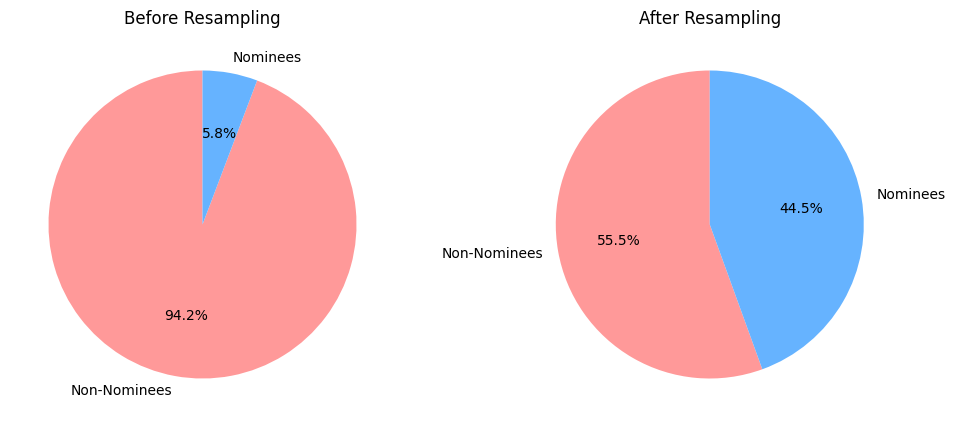

Input features: 27
Hidden layer size: (64,)
Total layers: 3
Output size: 1
Output activation: logistic
Best threshold: 0.7
Best parameters: {'mlp__alpha': 0.01, 'mlp__batch_size': 32, 'mlp__hidden_layer_sizes': (64,), 'rus__sampling_strategy': 0.8, 'smote__sampling_strategy': 0.5}


In [13]:
import matplotlib.pyplot as plt

stats_pipeline = Pipeline([
    ("smote", SMOTE(sampling_strategy=1/3,random_state=42)),
    ("rus", RandomUnderSampler(sampling_strategy=0.8,random_state=42)),
    ("scaler", StandardScaler()),
    ("mlp", MLPClassifier(solver='adam',
                    max_iter=500,
                    early_stopping=True,
                    hidden_layer_sizes=[(64,)],
                    alpha=0.0001,
                    batch_size=32,
                    validation_fraction=0.2,
                    random_state=42))
    ])

_, y_smote = stats_pipeline[:-3].fit_resample(X_train, y_train)
_, y_rus = stats_pipeline[:-2].fit_resample(X_train, y_train)

print(f"Original class distribution: Non-Nominee --> {Counter(y_train)[0]} Nominee --> {Counter(y_train)[1]} ")
print(f"After SMOTE: Non-Nominee --> {Counter(y_smote)[0]} Nominee --> {Counter(y_smote)[1]} ")
print(f"After RUS: Non-Nominee --> {Counter(y_rus)[0]} Nominee --> {Counter(y_rus)[1]} ")


counts = Counter(y_train)
sizes = [counts[0], counts[1]]
labels = ['Non-Nominees', 'Nominees']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90, colors=['#ff9999', '#66b3ff'])
ax1.set_title('Before Resampling')

counts = Counter(y_rus)
sizes = [counts[0], counts[1]]
labels = ['Non-Nominees', 'Nominees']

ax2.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90, colors=['#ff9999', '#66b3ff'])
ax2.set_title('After Resampling')

plt.show()

mlp = tuned_model.estimator_.best_estimator_["mlp"]

print("Input features:", mlp.n_features_in_)
print("Hidden layer size:", mlp.hidden_layer_sizes)
print("Total layers:", mlp.n_layers_)
print("Output size:", mlp.n_outputs_)
print("Output activation:", mlp.out_activation_)

print(f"Best threshold: {tuned_model.best_threshold_}")
print(f"Best parameters: {tuned_model.estimator_.best_params_}")

# **Evaluate**

Train Accuracy: 0.9258037922506183
Test Accuracy: 0.9276315789473685


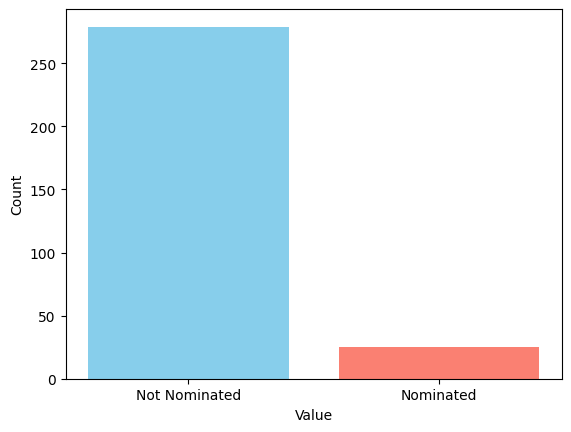

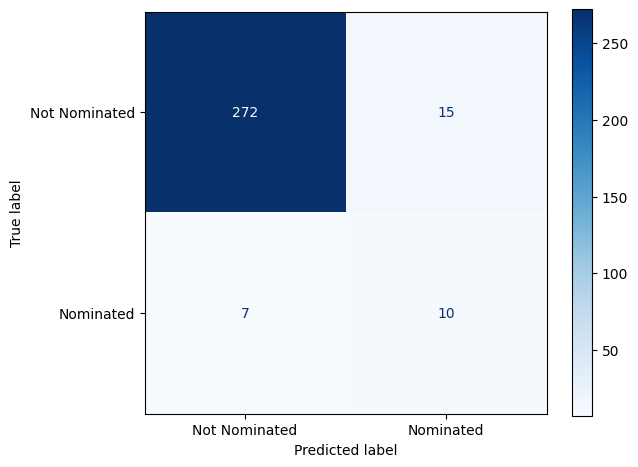

               precision    recall  f1-score   support

Not Nominated       0.97      0.95      0.96       287
    Nominated       0.40      0.59      0.48        17

     accuracy                           0.93       304
    macro avg       0.69      0.77      0.72       304
 weighted avg       0.94      0.93      0.93       304



In [16]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

print(f"Train Accuracy: {tuned_model.score(X_train, y_train)}")
print(f"Test Accuracy: {tuned_model.score(X_test, y_test)}")

y_pred = tuned_model.predict(X_test)
classes, counts = np.unique(y_pred, return_counts=True)

plt.bar(['Not Nominated', 'Nominated'], counts, color=['skyblue', 'salmon'])
plt.xlabel('Value')
plt.ylabel('Count')
plt.show()

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=['Not Nominated', 'Nominated'],
    xticks_rotation=0, cmap="Blues", values_format="d"
)
plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred, target_names=['Not Nominated', 'Nominated'], zero_division=0))
